# Chapter 5 · Eigenvalues and the SVD

*Book 1 · Linear Algebra · Shelf I*

**Builds on:** [Chapter 2](02-matrices-as-maps.ipynb) (matrices as maps) and
[Chapter 4](04-orthogonality-and-least-squares.ipynb) (orthonormal bases).
**You will:** find a matrix's eigenvector by power iteration, see the singular value
decomposition as rotate-stretch-rotate, and approximate a matrix by fewer numbers -- the idea the
book's challenge measures.

Most directions change under a map. An **eigenvector** does not: the map only stretches it,
$Av = \lambda v$. For a symmetric matrix the eigenvectors are orthogonal and describe the map
completely. The **SVD** extends that to every matrix, square or not.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import viz

viz.use_style()
rng = np.random.default_rng(5)

## Power iteration

Apply $A$ to a random vector again and again, rescaling each time. The component along the
eigenvector with the largest $|\lambda|$ grows fastest and takes over. It is how Google's first
PageRank was computed, on a matrix with billions of rows.

power iteration: 4.69428255 | numpy's largest eigenvalue: 4.69428255


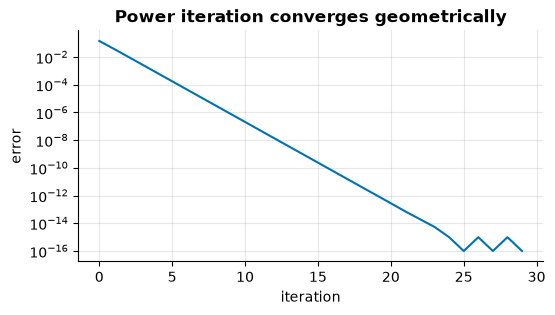

In [2]:
S = np.array([[4.0, 1.0, 0.5], [1.0, 3.0, 0.2], [0.5, 0.2, 1.0]])
v = rng.normal(size=3)
estimates = []
for _ in range(30):
    v = S @ v
    v /= np.linalg.norm(v)
    estimates.append(v @ S @ v)                   # the Rayleigh quotient
values, vectors = np.linalg.eigh(S)
print("power iteration:", round(estimates[-1], 8), "| numpy's largest eigenvalue:", round(values[-1], 8))
plt.figure(figsize=(6, 3))
plt.semilogy(np.abs(np.array(estimates) - values[-1]) + 1e-16)
plt.xlabel("iteration")
plt.ylabel("error")
plt.title("Power iteration converges geometrically");

The speed depends on the ratio of the two largest eigenvalues: the further apart, the faster.

## The SVD: rotate, stretch, rotate

Every matrix factors as $A = U \Sigma V^\top$: $V^\top$ rotates, $\Sigma$ stretches along the
axes by the **singular values** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$, and $U$ rotates again. A
circle becomes an ellipse whose half-axes are the singular values.

singular values: [2.4958 0.609 ] | U S V^T == A ? True


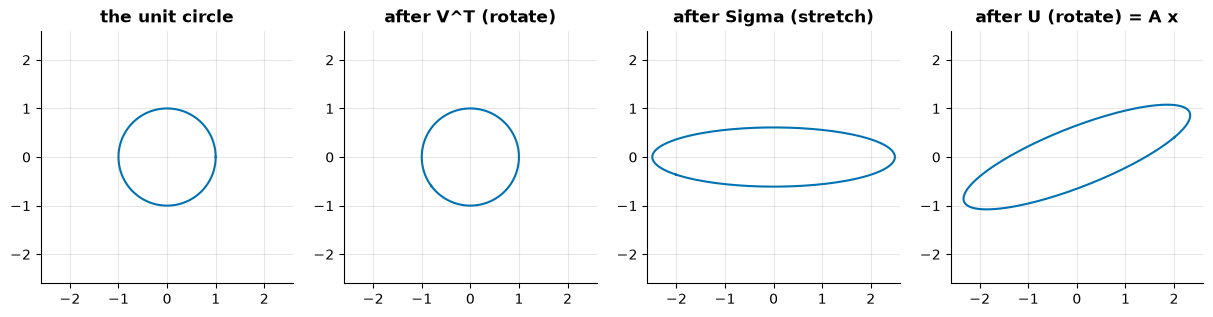

In [3]:
A = np.array([[2.0, 1.2], [0.4, 1.0]])
U, s, Vt = np.linalg.svd(A)
theta = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(theta), np.sin(theta)])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
steps = [("the unit circle", circle), ("after V^T (rotate)", Vt @ circle),
         ("after Sigma (stretch)", np.diag(s) @ Vt @ circle), ("after U (rotate) = A x", A @ circle)]
for ax, (title, pts) in zip(axes, steps, strict=True):
    ax.plot(*pts, color=viz.PALETTE[0])
    ax.set(aspect="equal", xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), title=title)
print("singular values:", s.round(4), "| U S V^T == A ?", np.allclose(U @ np.diag(s) @ Vt, A))

## The SVD, by hand

$A^\top A = V \Sigma^2 V^\top$: the right singular vectors are the eigenvectors of $A^\top A$,
the singular values the square roots of its eigenvalues. (Libraries do not compute it this way --
forming $A^\top A$ squares the condition number, chapter 4 -- but it shows where the SVD comes
from.)

In [4]:
B = rng.normal(size=(7, 4))
ev, V = np.linalg.eigh(B.T @ B)
order = np.argsort(ev)[::-1]
print("from A^T A:", np.sqrt(ev[order]).round(6))
print("np.linalg: ", np.linalg.svd(B, compute_uv=False).round(6))

from A^T A: [3.038811 2.584169 2.157971 1.617729]
np.linalg:  [3.038811 2.584169 2.157971 1.617729]


## Fewer numbers: the low-rank approximation

Keep only the $k$ largest singular values: $A_k = \sum_{i \le k} \sigma_i u_i v_i^\top$. The
**Eckart-Young theorem** says no matrix of rank $k$ is closer to $A$; the error is exactly what
the dropped singular values carry. A matrix whose singular values fall fast is well described by
a few of them.

Frobenius error of rank k vs sqrt(sum of dropped sigma^2):


  k=1: 16.6877 vs 16.6877
  k=2: 9.9016 vs 9.9016
  k=3: 9.8029 vs 9.8029
  k=5: 9.6142 vs 9.6142


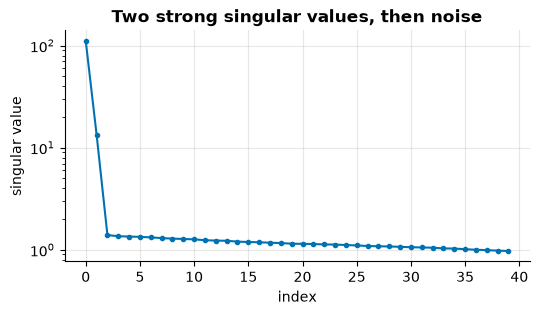

In [5]:
n = 200
t = np.linspace(0, 1, n)
smooth = np.outer(np.sin(3 * t), np.cos(2 * t)) + 0.5 * np.outer(t ** 2, np.sin(5 * t))
noisy = smooth + 0.05 * rng.normal(size=(n, n))
sv = np.linalg.svd(noisy, compute_uv=False)
U, s_, Vt = np.linalg.svd(noisy)
errs = [np.linalg.norm(noisy - (U[:, :k] * s_[:k]) @ Vt[:k]) for k in range(1, 11)]
print("Frobenius error of rank k vs sqrt(sum of dropped sigma^2):")
for k in (1, 2, 3, 5):
    print(f"  k={k}: {errs[k - 1]:.4f} vs {np.sqrt((sv[k:] ** 2).sum()):.4f}")
plt.figure(figsize=(6, 3))
plt.semilogy(sv[:40], marker=".")
plt.title("Two strong singular values, then noise")
plt.xlabel("index")
plt.ylabel("singular value");

Two singular values stand far above the rest: the smooth part has rank two, the rest is noise.
Keeping two numbers per row and column recovers the signal and drops most of the noise.

## What to remember

- Eigenvectors are the directions a map only stretches; power iteration finds the dominant one.
- The SVD is rotate-stretch-rotate, for every matrix.
- Truncating the SVD gives the best low-rank approximation; its error is what you dropped.

## Exercises

1. Compare `np.linalg.norm(smooth - rank-2 approximation of noisy)` with the noise level. Did the
   truncation denoise?
2. Make the two largest eigenvalues of `S` close. How many power iterations are needed now?
3. What are the singular values of a rotation matrix, and why?

**Next:** [Chapter 6 · PCA](06-pca.ipynb)